# chromVAR — TF Activity Scores

## Setup

Download a **MEME motif database file** containing human transcription factor binding motifs from the Cis-BP resource, alongside the **human genome** in fasta format.

In [1]:
%%bash
[ -f data/cisBP_human.meme ] || wget -O data/cisBP_human.meme https://osf.io/download/uk6vn
[ -f data/GRCh38.fa ] || wget -O data/GRCh38.fa.gz https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_38/GRCh38.p13.genome.fa.gz
[ -f data/GRCh38.fa ] || gunzip -c data/GRCh38.fa.gz > data/GRCh38.fa

In [2]:
import gatac as ga
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np

sc  .set_figure_params(dpi=100, frameon=False)

GENOME_FASTA = "data/GRCh38.fa"
MOTIF_FILE   = "data/cisBP_human.meme"

peak_adata = ad.read_h5ad("data/pbmc_peaks.h5ad")
print(peak_adata)

AnnData object with n_obs × n_vars = 5001 × 179702
    obs: 'barcode', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction', 'leiden', 'cell_type'
    obsm: 'X_umap'


## 1. Compute peak biases

GC content is used to stratify peaks into bins for background sampling,
ensuring that background peaks have similar GC content to the foreground.

16:24:35 - gatac.motif.chromvar - INFO - Computing peak biases from data/GRCh38.fa...


Fetching sequences for GC content:   0%|          | 0/179702 [00:00<?, ?it/s]

16:24:53 - gatac.motif.chromvar - INFO - Added 'gc_content' to adata.var


Peak bias computed in 17.9s


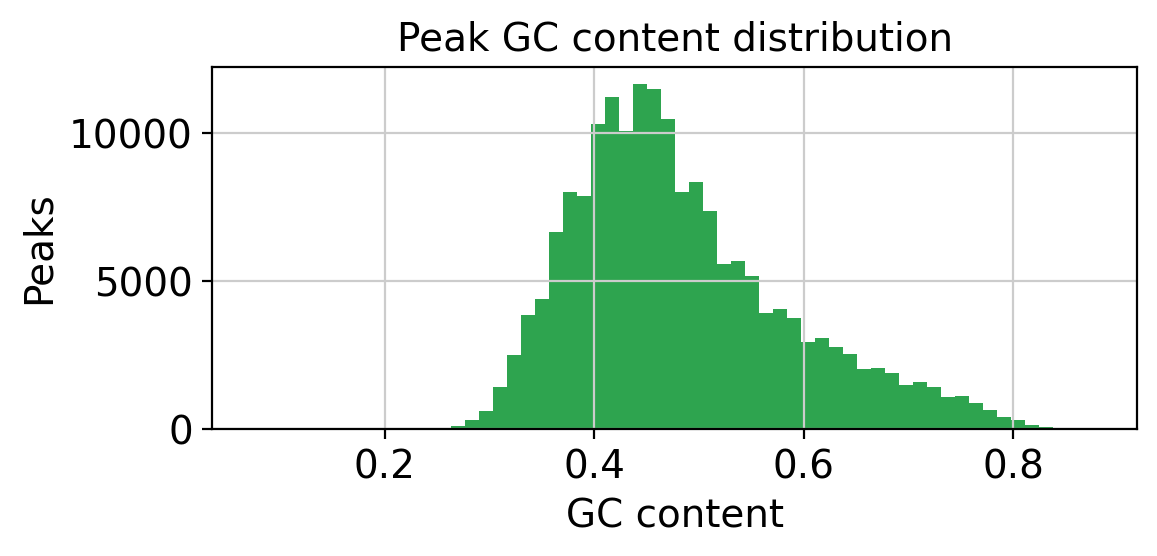

In [3]:
import time

t0 = time.perf_counter()
ga.motif.compute_peak_bias(peak_adata, genome_fasta=GENOME_FASTA, add_gc_content=True)
print(f"Peak bias computed in {time.perf_counter() - t0:.1f}s")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(peak_adata.var["gc_content"], bins=60, color="#2ea44f", edgecolor="none")
ax.set_xlabel("GC content")
ax.set_ylabel("Peaks")
ax.set_title("Peak GC content distribution")
plt.tight_layout()
plt.show()

## 2. Sample background peaks

In [4]:
ga.motif.sample_bg_peaks(peak_adata)

16:24:56 - gatac.motif.chromvar - INFO - Sampling background peaks using method 'knn'...


16:24:56 - gatac.motif.chromvar - INFO - Using cuML for k-NN background sampling...


16:25:02 - gatac.motif.chromvar - INFO - Sampled 50 background peaks for 179702 peaks. Stored in adata.varm['bg_peaks']


## 3. Run chromVAR

The full chromVAR pipeline — motif scanning, expectation computation, and
deviation scoring — runs entirely on GPU.

In [5]:
motifs = ga.motif.read(MOTIF_FILE, unique=True)
print(f"Loaded {len(motifs)} motifs")

ga.motif.scan(peak_adata, motifs, genome_fasta=GENOME_FASTA)

t0 = time.perf_counter()
ga.motif.compute_deviations(peak_adata)
print(f"chromVAR deviations computed in {time.perf_counter() - t0:.1f}s")
print(f"Deviation matrix: {peak_adata.obsm['chromvar'].shape}")

16:25:04 - gatac.motif.chromvar - INFO - Scanning 1165 motifs in 179702 peaks...


16:25:04 - gatac.motif.chromvar - INFO - Using 0-based coordinate system


16:25:04 - gatac.motif.chromvar - INFO - Fetching sequences from genome...


Loaded 1165 motifs


Fetching sequences:   0%|          | 0/179702 [00:00<?, ?it/s]

...

Processing cell chunks:   0%|          | 0/2 [00:00<?, ?it/s]

Processing cell chunks:   0%|          | 0/2 [00:00<?, ?it/s]

Processing cell chunks:   0%|          | 0/2 [00:00<?, ?it/s]

16:30:35 - gatac.motif.chromvar - INFO - Computed chromVAR deviations: (5001, 1165). Stored in adata.obsm['chromvar']


chromVAR deviations computed in 31.7s
Deviation matrix: (5001, 1165)


Another way to run the full chromvar pipeline in one command is to use:
```python
ga.motif.chromvar(peak_adata,genome_fasta=GENOME_FASTA,motifs_path=MOTIF_FILE)
```
This runs all steps 1 to 3.

## 4. Visualize TF activity on UMAP

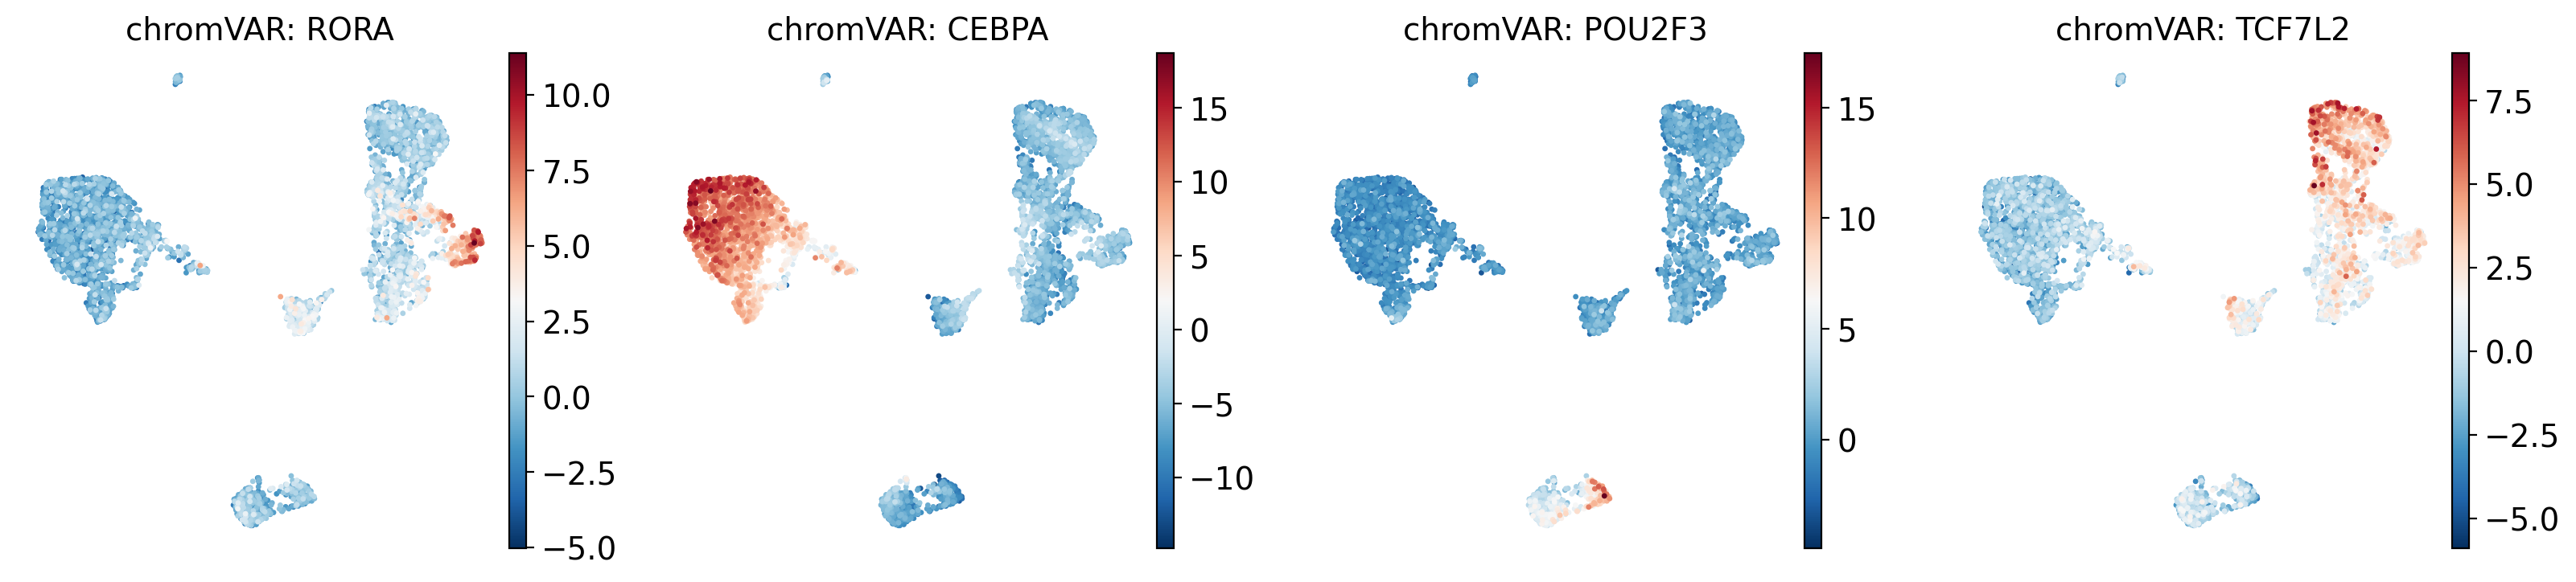

In [6]:
# Build a sub-AnnData with chromVAR scores for Scanpy plotting
import anndata as ad
import pandas as pd
import scipy.sparse as sp

motif_names = peak_adata.obsm['chromvar'].columns.tolist()
cv_adata = ad.AnnData(
    X=sp.csr_matrix(peak_adata.obsm["chromvar"]),
    obs=peak_adata.obs,
)
cv_adata.var_names = motif_names
cv_adata.obsm["X_umap"] = peak_adata.obsm["X_umap"]

# Plot top variable TFs
top_tfs = ["RORA", "CEBPA", "POU2F3", "TCF7L2"]
available = [tf for tf in top_tfs if tf in cv_adata.var_names]

if available:
    sc.pl.umap(cv_adata, color=available, ncols=4, cmap="RdBu_r",
               title=[f"chromVAR: {tf}" for tf in available])

## Next steps

- [05 – GSEA](05_gsea.ipynb): gene-set enrichment on ranked peaks
- [API: `ga.motif.chromvar`](../docs/api/motif.md#chromvar)